<a href="https://colab.research.google.com/github/saichandanss2190/ITA0615-Machine-Learning-192312190-/blob/main/Exp_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Generate Synthetic Car Dataset
np.random.seed(42)
n_samples = 1000

brands = ['Toyota', 'Honda', 'Ford', 'BMW', 'Audi', 'Chevrolet']
fuel_types = ['Gas', 'Diesel', 'Hybrid', 'Electric']

data = {
    'Brand': np.random.choice(brands, n_samples),
    'Year': np.random.randint(2010, 2024, n_samples),
    'Mileage': np.random.randint(5000, 150000, n_samples),
    'EngineSize': np.round(np.random.uniform(1.0, 4.5, n_samples), 1),
    'FuelType': np.random.choice(fuel_types, n_samples, p=[0.6, 0.15, 0.15, 0.10])
}

df = pd.DataFrame(data)

# Generate a realistic Price column with some noise
# Base price + Brand premium + Year effect - Mileage effect + Engine size bonus
brand_premium = {'Toyota': 15000, 'Honda': 16000, 'Ford': 14000, 'BMW': 30000, 'Audi': 28000, 'Chevrolet': 13000}
fuel_bonus = {'Gas': 0, 'Diesel': 1500, 'Hybrid': 3000, 'Electric': 8000}

df['Price'] = df['Brand'].map(brand_premium) + \
              (df['Year'] - 2010) * 1200 - \
              (df['Mileage'] * 0.08) + \
              (df['EngineSize'] * 4000) + \
              df['FuelType'].map(fuel_bonus) + \
              np.random.normal(0, 2000, n_samples)

# Clip negative prices if any (unlikely with these parameters)
df['Price'] = df['Price'].clip(lower=2000)

print("Dataset Sample:")
display(df.head())

Dataset Sample:


,Brand,Year,Mileage,EngineSize,FuelType,Price
0,BMW,2015,53901,3.6,Gas,49205.362426
1,Audi,2014,104986,3.8,Gas,37426.975247
2,Ford,2015,133386,4.0,Gas,24456.401063
3,Audi,2015,10626,1.9,Gas,35934.183346
4,Audi,2016,143496,1.1,Gas,26528.940474


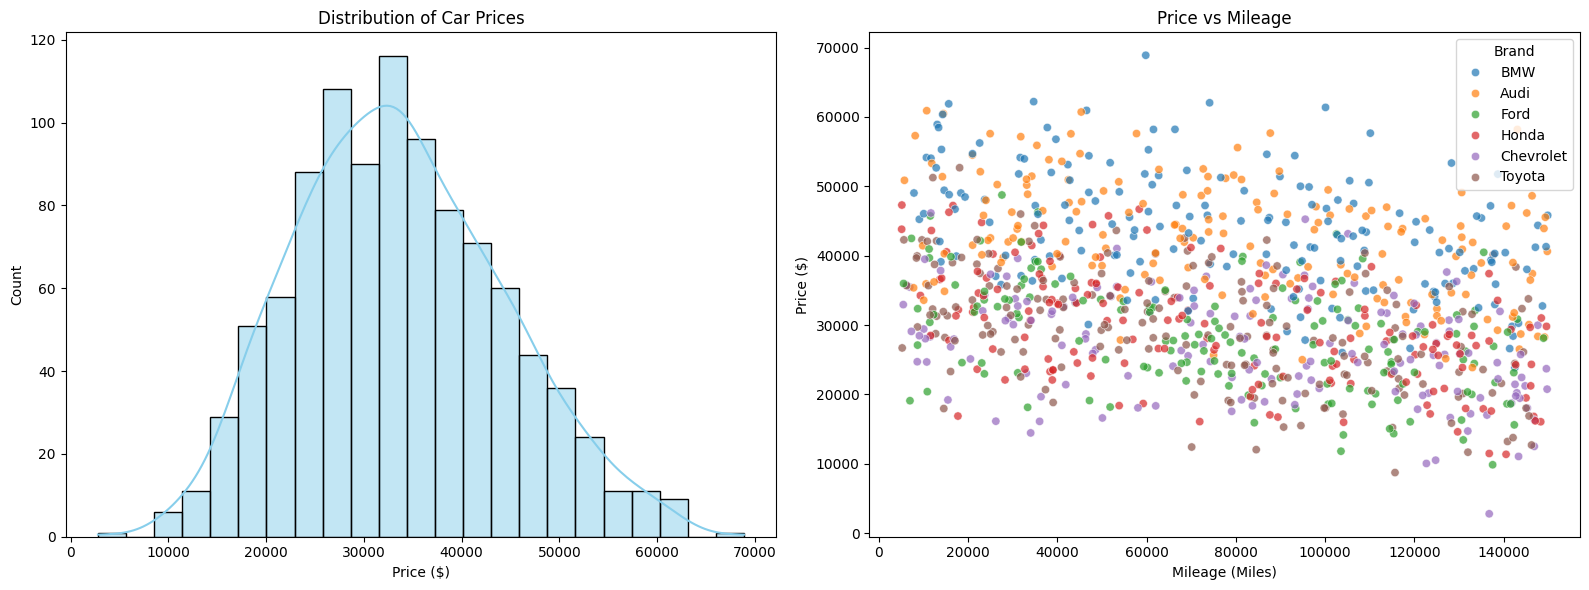

In [2]:
# 2. Exploratory Data Analysis (EDA)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution of Prices
sns.histplot(df['Price'], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Distribution of Car Prices')
axes[0].set_xlabel('Price ($)')

# Price vs Mileage by Brand
sns.scatterplot(data=df, x='Mileage', y='Price', hue='Brand', alpha=0.7, ax=axes[1])
axes[1].set_title('Price vs Mileage')
axes[1].set_xlabel('Mileage (Miles)')
axes[1].set_ylabel('Price ($)')

plt.tight_layout()
plt.show()

In [3]:
# 3. Data Splitting & Pipeline Construction
X = df.drop(columns=['Price'])
y = df['Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define Preprocessing for Categorical Features
categorical_features = ['Brand', 'FuelType']
numerical_features = ['Year', 'Mileage', 'EngineSize']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(drop='first'), categorical_features)
    ])

# Define Model Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
])

# Train Model
model_pipeline.fit(X_train, y_train)
print("Model training completed successfully!")

Model training completed successfully!


        MODEL PERFORMANCE SUMMARY        
  Mean Absolute Error (MAE)  : $3,397.97
  Root Mean Squared Error    : $4,378.40
  R-squared (R²) Score       : 0.8282  (82.8% variance explained)


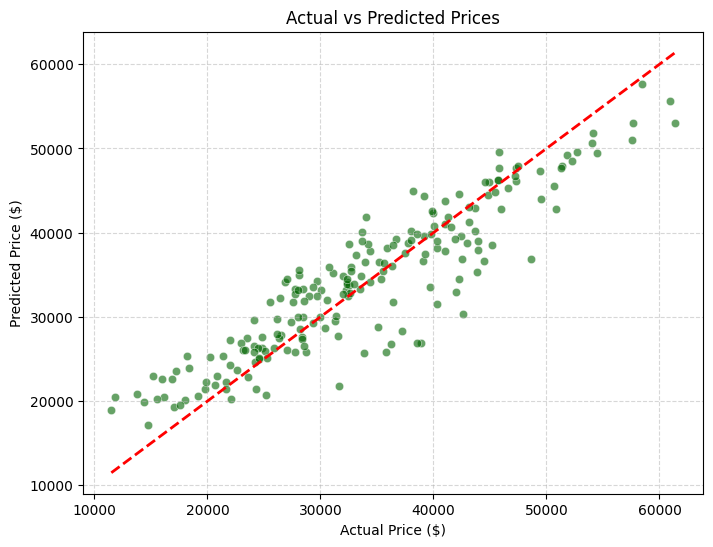

In [4]:
# 4. Model Evaluation & Visual Output
y_pred = model_pipeline.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Presentable Metrics Display
print("="*40)
print("        MODEL PERFORMANCE SUMMARY        ")
print("="*40)
print(f"  Mean Absolute Error (MAE)  : ${mae:,.2f}")
print(f"  Root Mean Squared Error    : ${rmse:,.2f}")
print(f"  R-squared (R²) Score       : {r2:.4f}  ({r2*100:.1f}% variance explained)")
print("="*40)

# Plotting Predicted vs Actual Prices
plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.6, color='darkgreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title('Actual vs Predicted Prices')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()